Calculating perturbations...
Time: 0.0000 | Sliced z at 0.006


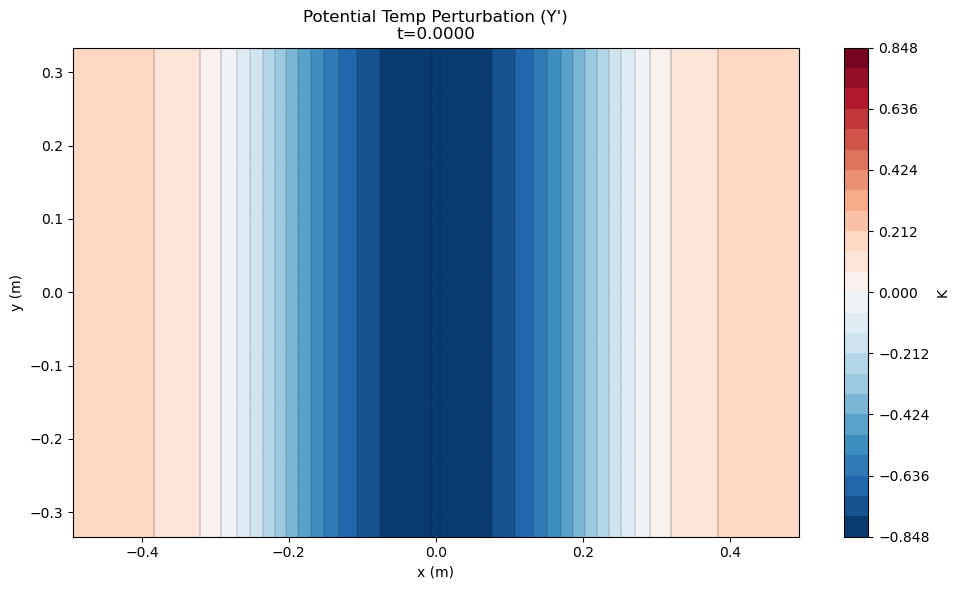

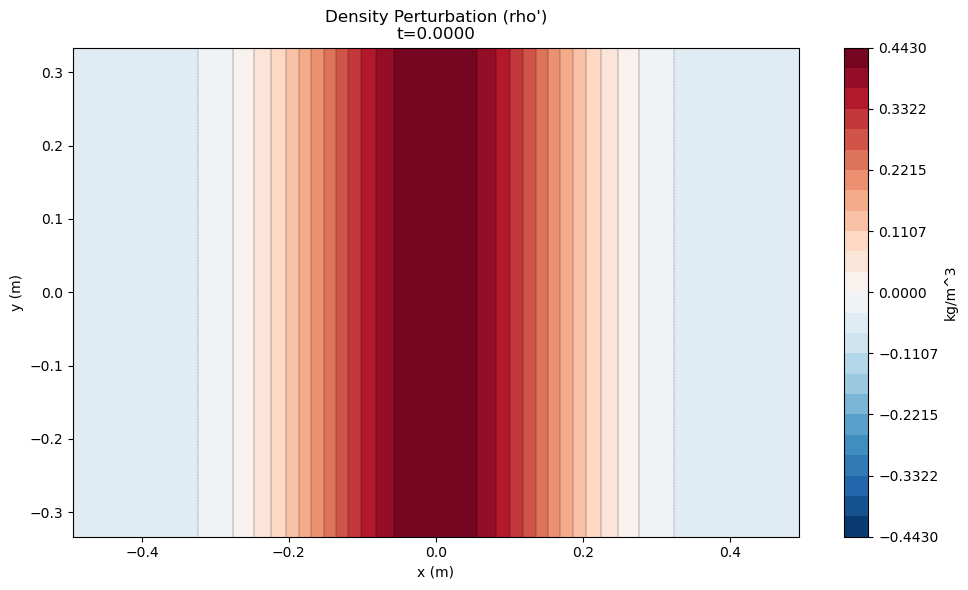

In [13]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import warnings

# Suppress xarray FutureWarnings
warnings.filterwarnings("ignore", category=FutureWarning)

# ==========================================
# 1. USER CONFIGURATION
# ==========================================
file_path = '/home/amir/Projects/Python/Atmpy/atmpy/output_data/baroclinic_qg_vortex/_baroclinic_qg_vortex_40_10_40_N_50_cor_500_QG_on_p_5_Hfac_4_projection.nc'
file_path = '/home/amir/Projects/Python/Atmpy/atmpy/output_data/baroclinic_qg_vortex/_baroclinic_qg_vortex_40_10_40.nc'
file_path = "/home/amir/Projects/Python/Atmpy/atmpy/output_data/traveling_vortex_3d/asymptotics/80_3_80_full/redundant2/_traveling_vortex_3d_80_3_80_cor_10000.nc"


time_index = 0      # Last time step
slice_dim = 'z'       # Slicing along Z to see the X-Y plane
slice_val = 0.0       # Center of domain
var1 = "Y"
var2 = "rho"

# ==========================================
# 2. DATA PROCESSING
# ==========================================
ds = xr.open_dataset(file_path, decode_times=False)
ds_step = ds.isel(time=time_index)
t_val = ds_step['time'].values

# Load variables
Y = ds_step[var1]
rho = ds_step[var2]

# Calculate Perturbations (Field - Horizontal Mean)
print("Calculating perturbations...")
Y_bg = Y.mean(dim=['x', 'z'])
rho_bg = rho.mean(dim=['x', 'z'])
Y_prime = Y - Y_bg
rho_prime = rho - rho_bg

# Slice the data
Y_slice = Y_prime.sel({slice_dim: slice_val}, method='nearest')
rho_slice = rho_prime.sel({slice_dim: slice_val}, method='nearest')
actual_slice = float(Y_slice[slice_dim].values)

print(f"Time: {t_val:.4f} | Sliced {slice_dim} at {actual_slice:.3f}")

# ==========================================
# 3. PLOTTING FUNCTION (Contour Style)
# ==========================================
def plot_contour_style(ax, data_array, title, unit):
    """
    Plots data using filled contours + thin black overlay lines
    to match visualize.py style.
    """
    # 1. Identify Axes
    # We want Simulation X -> Plot Horizontal
    # We want Simulation Y -> Plot Vertical
    x_coord = data_array['x'].values
    y_coord = data_array['y'].values

    # Transpose data to shape (Y, X) for matplotlib (Rows=Y, Cols=X)
    # This ensures orientation is correct regardless of internal storage
    z_data = data_array.transpose('y', 'x').values

    # 2. Setup Levels
    # Find max amplitude for symmetric centering (since these are perturbations)
    lim = float(np.abs(z_data).max())
    # 25 levels as per your visualize.py
    levels = np.linspace(-lim, lim, 25)

    # 3. Filled Contours
    # Using RdBu_r (Red-Blue reversed) is standard for +/- perturbations
    cf = ax.contourf(x_coord, y_coord, z_data, levels=levels, cmap='RdBu_r')

    # 4. Line Contours Overlay (The "High Res" look from visualize.py)
    # colors='k', linewidths=0.2
    ax.contour(x_coord, y_coord, z_data, levels=levels, colors='k', linewidths=0.2)

    # 5. Decoration
    cbar = plt.colorbar(cf, ax=ax)
    cbar.set_label(unit)

    # Clean up ticks to match visualize.py style (optional)
    # cbar.ax.set_yticklabels([f"{t:.2e}" for t in cbar.get_ticks()])

    ax.set_title(title)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

# ==========================================
# 4. GENERATE PLOTS
# ==========================================

# Plot 1: Potential Temperature
fig1, ax1 = plt.subplots(figsize=(10, 6))
plot_contour_style(
    ax1,
    Y_slice,
    f"Potential Temp Perturbation (Y')\nt={t_val:.4f}",
    "K"
)
plt.tight_layout()
plt.show()

# Plot 2: Density
fig2, ax2 = plt.subplots(figsize=(10, 6))
plot_contour_style(
    ax2,
    rho_slice,
    f"Density Perturbation (rho')\nt={t_val:.4f}",
    "kg/m^3"
)
plt.tight_layout()
plt.show()

In [6]:
ds.close()
print("Datasets closed.")

Datasets closed.
